In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV,KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc


In [2]:
df = pd.read_csv("Covid Dataset.csv")
df1 = df.dropna()
df1.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Covid Dataset.csv'

In [3]:

for i in df1.columns:
    df1[i] = df1[i].apply(lambda x: 1 if x == "Yes" else 0)


NameError: name 'df1' is not defined

In [ ]:

Y = df1["COVID-19"]
X = df1.drop("COVID-19", axis=1)

In [ ]:
model = LogisticRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []

for train_index, test_index in kf.split(X):
    # Split data into training and testing sets
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]
    
    # Train the model
    model.fit(X_train, Y_train)
    
    # Test the model
    predictions = model.predict(X_test)
    
    acc = accuracy_score(Y_test, predictions)
    accuracy_scores.append(acc)


print("Accuracy per fold:", accuracy_scores)

print("\nAverage accuracy:", np.mean(accuracy_scores))



Accuracy per fold: [0.9724011039558418, 0.9604415823367065, 0.9724011039558418, 0.9705611775528978, 0.9640883977900553]

Average accuracy: 0.9679786731182686


In [13]:
model1 = LogisticRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

for train_index, test_index in kf.split(X):
  
    X_train1, X_test1 = X.iloc[train_index], X.iloc[test_index]
    Y_train1, Y_test1 = Y.iloc[train_index], Y.iloc[test_index]
    
    model1.fit(X_train1, Y_train1)
    predictions = model1.predict(X_test1)
    
    acc = accuracy_score(Y_test1, predictions)
    precision = precision_score(Y_test1, predictions)
    recall = recall_score(Y_test1, predictions)
    f1 = f1_score(Y_test1, predictions)
    
    accuracy_scores.append(acc)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

print("Accuracy per fold:", accuracy_scores)
print("Precision per fold:", precision_scores)
print("Recall per fold:", recall_scores)
print("F1-Score per fold:", f1_scores)

print("\nAverage Accuracy: {:.4f}".format(np.mean(accuracy_scores)))
print("Average Precision: {:.4f}".format(np.mean(precision_scores)))
print("Average Recall: {:.4f}".format(np.mean(recall_scores)))
print("Average F1-Score: {:.4f}".format(np.mean(f1_scores)))

Accuracy per fold: [0.9724011039558418, 0.9604415823367065, 0.9724011039558418, 0.9705611775528978, 0.9640883977900553]
Precision per fold: [0.9755011135857461, 0.9609375, 0.9826589595375722, 0.9778024417314095, 0.9695603156708005]
Recall per fold: [0.9909502262443439, 0.9907940161104718, 0.9826589595375722, 0.986562150055991, 0.9862385321100917]
F1-Score per fold: [0.9831649831649831, 0.9756373937677054, 0.9826589595375722, 0.9821627647714605, 0.9778283115406481]

Average Accuracy: 0.9680
Average Precision: 0.9733
Average Recall: 0.9874
Average F1-Score: 0.9803


In [ ]:
# Initialize Logistic Regression model with default parameters
model2 = LogisticRegression(random_state=42, max_iter=2000)


param_grid = {
    'C': np.arange(0.7001, 1.0001, 0.0001), 
    'penalty': ['l2'], 
    'solver': ['lbfgs']  }

grid_search = GridSearchCV(model, param_grid, verbose=2, cv=kf)


grid_search.fit(X_train, Y_train)


best_params = grid_search.best_params_
print(f"Best Parameters: {best_params}")

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 3001 candidates, totalling 15005 fits
[CV] END .................C=0.7001, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .................C=0.7001, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .................C=0.7001, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .................C=0.7001, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .................C=0.7001, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .....C=0.7001999999999999, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .....C=0.7001999999999999, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .....C=0.7001999999999999, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .....C=0.7001999999999999, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .....C=0.7001999999999999, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .....C=0.7002999999999999, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END .....C=0.7002999999999999, penalty

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, accuracy_score, recall_score, precision_score, f1_score


scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score),
    'f1': make_scorer(f1_score)
}

# use cross_validate to do k_fold cross validation
cv_results = cross_validate(best_model, X_train, Y_train, cv=kf, scoring=scoring, return_train_score=False)


print(f"Average Accuracy: {cv_results['test_accuracy'].mean():.4f}")
print(f"Average Precision: {cv_results['test_precision'].mean():.4f}")
print(f"Average Recall: {cv_results['test_recall'].mean():.4f}")
print(f"Average F1-Score: {cv_results['test_f1'].mean():.4f}")


Average Accuracy: 0.9687
Average Precision: 0.9760
Average Recall: 0.9855
Average F1-Score: 0.9807


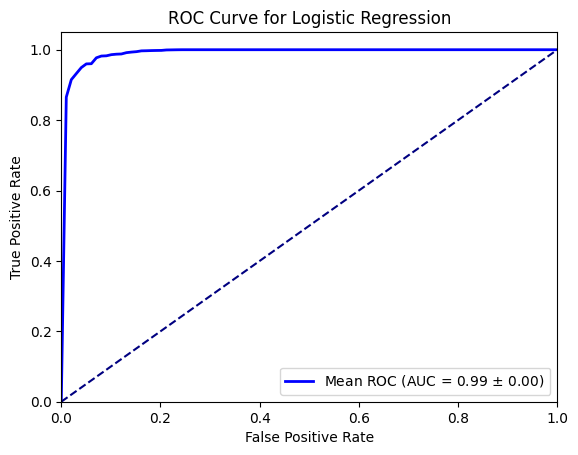

In [ ]:
# Initialize lists for FPR and TPR
tprs = []
mean_fpr = np.linspace(0, 1, 100)
roc_auc_list = []

for train_index, test_index in kf.split(X):
    
    X_train2, X_test2 = X.iloc[train_index], X.iloc[test_index]
    y_train2, y_test2 = Y.iloc[train_index], Y.iloc[test_index]
    
    model1.fit(X_train2, y_train2)
    
    # Predict probabilities for ROC curve
    y_test_proba = best_model.predict_proba(X_test2)[:, 1]
    
    # Compute ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test2, y_test_proba)
    roc_auc = auc(fpr, tpr)
    roc_auc_list.append(roc_auc)
    
    # Interpolate TPR values for a common FPR range
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0  

# Calculate the mean TPR and its standard deviation
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0  
std_tpr = np.std(tprs, axis=0)

# Compute mean ROC AUC
mean_auc = np.mean(roc_auc_list)
std_auc = np.std(roc_auc_list)

# Plot the mean ROC curve
plt.figure()
plt.plot(mean_fpr, mean_tpr, color='b', label=r'Mean ROC (AUC = %0.2f $\pm$ %0.2f)' % (mean_auc, std_auc), lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')

#plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Logistic Regression')
plt.legend(loc='lower right')
plt.show()